In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/synthetic_nepal_sales.csv")

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Display data types
print(df.dtypes)

StoreID                  int64
Store                   object
DeptID                   int64
Dept                    object
Date            datetime64[ns]
Weekly_Sales           float64
IsHoliday                 bool
Holiday_Name            object
Store_Type              object
Store_Size               int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object


In [3]:
numeric_columns = [
    "Weekly_Sales",
    "Store_Size",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Weekly_Sales,235000.0,6745.312200,2240.093580,2164.720000,5153.950000,6295.745000,7838.657500,26240.980000
Store_Size,235000.0,1856.400000,1090.906093,880.000000,1150.000000,1400.000000,2000.000000,5000.000000
Temperature,235000.0,17.340565,6.549489,-0.998664,11.344014,18.896851,22.948838,32.404052
Fuel_Price,235000.0,1.215507,0.150149,0.855117,1.099198,1.192731,1.361729,1.563524
CPI,235000.0,112.335945,8.601327,95.810766,105.333181,111.056585,118.710359,131.289893
Unemployment,235000.0,3.843464,0.362427,2.865239,3.570558,3.802708,4.074685,5.038595


In [4]:
for col in numeric_columns:
    print(f"\n{col}")
    print("Negative values:", (df[col] < 0).sum())
    print("Zero values:", (df[col] == 0).sum())


Weekly_Sales
Negative values: 0
Zero values: 0

Store_Size
Negative values: 0
Zero values: 0

Temperature
Negative values: 3
Zero values: 0

Fuel_Price
Negative values: 0
Zero values: 0

CPI
Negative values: 0
Zero values: 0

Unemployment
Negative values: 0
Zero values: 0


In [5]:
outlier_results = []

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (len(outliers) / len(df)) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Weekly_Sales,1126.888750,11865.718750,7899,3.361277
1,Store_Size,-125.000000,3275.000000,28200,12.000000
2,Temperature,-6.063223,40.356075,0,0.000000
3,Fuel_Price,0.705402,1.755525,0,0.000000
4,CPI,85.267414,138.776126,0,0.000000
5,Unemployment,2.814367,4.830876,365,0.155319


In [6]:
high_sales = df.nlargest(10, "Weekly_Sales")[
    [
        "Store",
        "Dept",
        "Date",
        "Weekly_Sales",
        "IsHoliday",
        "Holiday_Name",
        "Store_Type",
        "Store_Size"
    ]
]

high_sales

,Store,Dept,Date,Weekly_Sales,IsHoliday,Holiday_Name,Store_Type,Store_Size
11242,Bhat-Bhateni,Bakery,2024-04-14,26240.98,True,Nepali New Year,A,5000
1837,Kathmandu Mart,Bakery,2024-03-10,23700.87,True,Holi,A,3500
11237,Bhat-Bhateni,Bakery,2024-03-10,23592.25,True,Holi,A,5000
18031,Bhat-Bhateni,Household Care,2019-04-14,23184.37,True,Nepali New Year,A,5000
8921,Kathmandu Mart,Household Care,2024-11-03,22980.30,True,Tihar,A,3500
18183,Bhat-Bhateni,Household Care,2022-03-13,22867.99,True,Holi,A,5000
152271,CityCenter KTM,Bakery,2024-11-03,22307.42,True,Tihar,A,4200
17381,Bhat-Bhateni,Fruits,2024-11-03,22167.95,True,Tihar,A,5000
152028,CityCenter KTM,Bakery,2020-03-08,21927.42,True,Holi,A,4200
18269,Bhat-Bhateni,Household Care,2023-11-05,21760.94,True,Tihar,A,5000


In [7]:
print("Unique store sizes:")
print(sorted(df["Store_Size"].unique()))

print("\nStore size by store:")
print(
    df.groupby("Store")["Store_Size"]
      .first()
      .sort_values(ascending=False)
)

Unique store sizes:
[880, 900, 950, 980, 1000, 1100, 1150, 1200, 1250, 1300, 1350, 1400, 1450, 1500, 1600, 1700, 1800, 2000, 2800, 3000, 3200, 3500, 4200, 5000]

Store size by store:
Store
Bhat-Bhateni           5000
CityCenter KTM         4200
Kathmandu Mart         3500
Himalayan Hyper        3200
Pokhara BigMart        3000
Saleways Nepal         2800
Lalitpur Market        2000
Pokhara Plaza          1800
Hetauda Hyper          1700
KK Mart                1600
Butwal SuperMart       1500
Midland Mart           1450
Biratnagar Mart        1400
Chitwan SuperCenter    1350
Itahari Center         1300
Bhairahawa Mall        1250
Dharan Plaza           1200
Northern Market        1200
Eastern Plaza          1150
Nepalgunj Market       1100
Janakpur Mart          1000
Western Super           980
Township Mart           950
Birgunj Mart            900
Southern Bazaar         880
Name: Store_Size, dtype: int64


In [8]:
unemployment_extremes = pd.concat([
    df.nsmallest(10, "Unemployment"),
    df.nlargest(10, "Unemployment")
])

unemployment_extremes[
    [
        "Store",
        "Date",
        "Unemployment",
        "Weekly_Sales",
        "Store_Type",
        "IsHoliday",
        "Holiday_Name"
    ]
]

,Store,Date,Unemployment,Weekly_Sales,Store_Type,IsHoliday,Holiday_Name
133984,Birgunj Mart,2016-08-28,2.865239,4618.49,C,False,NaN
11281,Bhat-Bhateni,2016-01-10,2.865760,12422.47,A,False,NaN
82281,Nepalgunj Market,2016-08-07,2.878161,3247.58,C,True,Janai Purnima
199759,Midland Mart,2016-03-06,2.893752,6196.83,B,False,NaN
136777,Birgunj Mart,2016-02-21,2.897105,6016.92,C,False,NaN
72871,Dharan Plaza,2016-05-29,2.897485,4989.03,C,False,NaN
142416,Saleways Nepal,2016-02-14,2.900315,12746.39,A,True,Valentine's Day
155122,CityCenter KTM,2016-06-05,2.908664,7150.20,A,False,NaN
69115,Dharan Plaza,2016-06-26,2.909124,5577.26,C,False,NaN
51736,Biratnagar Mart,2016-09-11,2.910476,4150.50,C,True,Teej


In [9]:
yearly_unemployment = (
    df.groupby(df["Date"].dt.year)["Unemployment"]
      .agg(["mean", "min", "max"])
      .round(3)
)

yearly_unemployment

,mean,min,max
Date,,,
2016,3.399,2.865,3.975
2017,3.499,2.911,4.074
2018,3.600,3.040,4.155
2019,3.699,3.079,4.392
2020,4.500,3.880,5.039
2021,4.198,3.510,4.802
2022,3.999,3.371,4.564
2023,3.901,3.329,4.498
2024,3.801,3.247,4.374


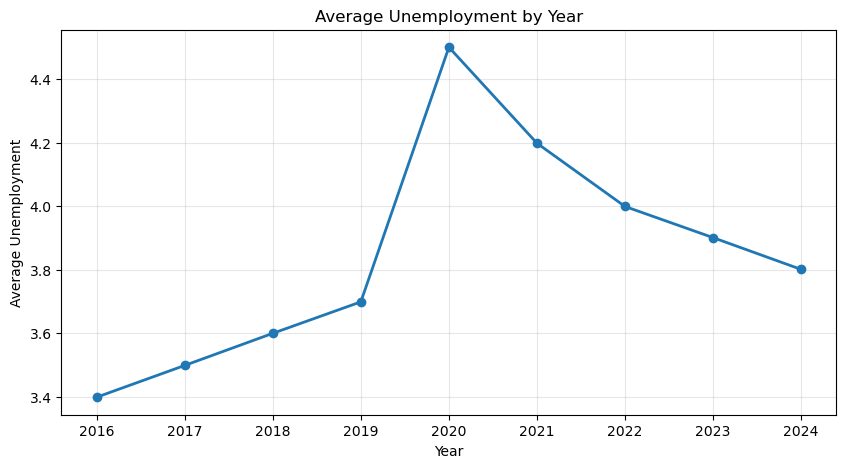

In [12]:
plt.figure(figsize=(10, 5))

yearly_unemployment["mean"].plot(
    marker="o",
    linewidth=2
)

plt.title("Average Unemployment by Year")
plt.xlabel("Year")
plt.ylabel("Average Unemployment")
plt.grid(True, alpha=0.3)

plt.xticks(yearly_unemployment.index)

plt.show()

In [13]:
categorical_columns = [
    "Store",
    "Dept",
    "Store_Type",
    "Holiday_Name"
]

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts().head(20))


Store
Unique values: 25
Store
Kathmandu Mart         9400
Pokhara BigMart        9400
Southern Bazaar        9400
Western Super          9400
Midland Mart           9400
Eastern Plaza          9400
Himalayan Hyper        9400
Township Mart          9400
KK Mart                9400
CityCenter KTM         9400
Saleways Nepal         9400
Birgunj Mart           9400
Chitwan SuperCenter    9400
Bhat-Bhateni           9400
Bhairahawa Mall        9400
Itahari Center         9400
Janakpur Mart          9400
Nepalgunj Market       9400
Dharan Plaza           9400
Hetauda Hyper          9400
Name: count, dtype: int64

Dept
Unique values: 20
Dept
Grocery                 11750
Vegetables              11750
Household Care          11750
Frozen Foods            11750
Fruits                  11750
Hardware                11750
Mobile & Accessories    11750
Beverages               11750
Meat                    11750
Beauty                  11750
Stationery              11750
Toys                    

In [14]:
# Check StoreID-to-Store mapping
store_mapping = df.groupby("StoreID")["Store"].nunique()

print("StoreIDs linked to multiple store names:", (store_mapping > 1).sum())

# Check DeptID-to-Dept mapping
dept_mapping = df.groupby("DeptID")["Dept"].nunique()

print("DeptIDs linked to multiple department names:", (dept_mapping > 1).sum())

# Check whether store information remains consistent
store_metadata = df.groupby("Store")[
    ["Store_Type", "Store_Size"]
].nunique()

print("\nStores with inconsistent metadata:")
print(store_metadata[(store_metadata > 1).any(axis=1)])

StoreIDs linked to multiple store names: 0
DeptIDs linked to multiple department names: 0

Stores with inconsistent metadata:
Empty DataFrame
Columns: [Store_Type, Store_Size]
Index: []


In [15]:
expected_rows = (
    df["StoreID"].nunique()
    * df["DeptID"].nunique()
    * df["Date"].nunique()
)

actual_rows = len(df)

print("Expected rows:", expected_rows)
print("Actual rows:", actual_rows)
print("Missing combinations:", expected_rows - actual_rows)

Expected rows: 235000
Actual rows: 235000
Missing combinations: 0


In [16]:
cleaned_df = df.copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)
print("Data copied successfully:", cleaned_df.equals(df))

Original dataset shape: (235000, 14)
Cleaned dataset shape: (235000, 14)
Data copied successfully: True


In [17]:
cleaned_df.to_csv(
    "../data/cleaned/nepal_supermarket_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
